In [ ]:
# !pip install fcapy[all]
# !pip install frozendict
# !pip install ipynb
# !pip install sparselinear
# !pip install bitsets
# !pip install bitarray
# import torch
# !pip install torch-scatter -f https://data.pyg.org/whl/torch-2.0.0+cuda118.html
# !pip install torch-sparse -f https://data.pyg.org/whl/torch-2.0.0+cuda118.html
# !pip install torch-cluster -f https://data.pyg.org/whl/torch-2.0.0+cuda118.html
# !pip install git+https://github.com/pyg-team/pytorch_geometric.git

# Neural FCA - Big Homework Solution

This notebook presents a comprehensive solution for building an interpretable classifier using Neural Formal Concept Analysis. The workflow proceeds as follows:

1.  Data Preparation: Preprocessing the Heart Disease UCI dataset using logical binarization and quantile scaling.
2.  Baseline Benchmarking: Evaluating standard classifiers (Logistic Regression, Random Forest, SVM, XGBoost) to establish performance baselines.
3.  Neural FCA Implementation: Constructing the base neural network architecture using formal concepts selected by F1-score.
4.  Initial Evaluation & Visualization: Analyzing early results and visualizing active decision paths within the concept lattice.
5.  Model Refinement: Implementing improvements such as:
    * Retraining Baselines: Utilizing the full attribute set.
    * Advanced Pipelines: Integrating validation sets and regularization.
    * Bagging Ensembles: Developing sparser, more interpretable networks through bootstrap aggregating.
6.  Final Results: A comprehensive performance comparison of all Neural FCA modifications.
7.  Analysis: Concluding remarks on model interpretability and metric evaluation.

## 0.5. Imports and Configuration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy
import torch
import torch.nn as nn
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from fcapy.context import FormalContext
from fcapy.lattice import ConceptLattice
from fcapy.visualizer import LineVizNx

import neural_fca.network as nl
import neural_fca.network as nl_new


warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8')

torch.manual_seed(42)
np.random.seed(42)

## 1. Data Preparation
(Data Loading & Binarization Strategy)

**Dataset:** Heart Disease UCI.  
**Target:** `target` (Presence of heart disease).
**Scaling:** Quantile Binning (3 bins) for continuous variables, One-Hot Encoding for categorical.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

from fcapy.context import FormalContext
from fcapy.lattice import ConceptLattice

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

names = [
    'age',      # numeric
    'sex',      # binary (0/1)
    'cp',       # categorical (4 значения)
    'trestbps', # numeric
    'chol',     # numeric
    'fbs',      # binary (0/1)
    'restecg',  # categorical (3 значения)
    'thalach',  # numeric
    'exang',    # binary (0/1)
    'oldpeak',  # numeric (float)
    'slope',    # categorical (3 значения)
    'ca',       # numeric (0–3, порядковый)
    'thal',     # categorical (3 значения)
    'target'    # 0..4
]

df = pd.read_csv(url, names=names, na_values="?")

In [ ]:
df = df.dropna().reset_index(drop=True)

df['target'] = (df['target'] > 0).astype(int)

categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
numerical_features   = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']

X = df.drop('target', axis=1)
y = df['target']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('discretizer', KBinsDiscretizer(
        n_bins=3,
        encode='onehot-dense',
        strategy='quantile'
    ))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

X_train_bin = preprocessor.fit_transform(X_train_raw)
X_test_bin  = preprocessor.transform(X_test_raw)

feature_names = preprocessor.get_feature_names_out()

X_train_full = pd.DataFrame(
    X_train_bin,
    columns=feature_names,
    index=X_train_raw.index
).astype(bool)

X_test_full = pd.DataFrame(
    X_test_bin,
    columns=feature_names,
    index=X_test_raw.index
).astype(bool)

print(f"Original Shape: {df.shape}")
print(f"Binary Shape (train): {X_train_full.shape}, Binary Shape (test): {X_test_full.shape}")

Original Shape: (297, 14)
Binary Shape (train): (237, 36), Binary Shape (test): (60, 36)


In [ ]:
corrs = {}
y_arr = y_train.to_numpy()

for col in X_train_full.columns:
    x = X_train_full[col].astype(int).to_numpy()
    if x.std() == 0:
        corrs[col] = 0.0
    else:
        c = np.corrcoef(x, y_arr)[0, 1]
        corrs[col] = abs(c)

sorted_attrs = sorted(corrs.keys(), key=lambda c: corrs[c], reverse=True)

attr_subset_size = min(10, len(sorted_attrs))
attrs_fca = sorted_attrs[:attr_subset_size]

print("Top attributes for FCA:")
for a in attrs_fca:
    print(f"  {a}: |corr|={corrs[a]:.3f}")

X_train = X_train_full[attrs_fca]
X_test  = X_test_full[attrs_fca]


Top attributes for FCA:
  cat__thal_3.0: |corr|=0.525
  cat__cp_4.0: |corr|=0.519
  cat__thal_7.0: |corr|=0.489
  num__ca_0.0: |corr|=0.437
  num__ca_1.0: |corr|=0.437
  cat__slope_1.0: |corr|=0.397
  cat__exang_0.0: |corr|=0.397
  cat__exang_1.0: |corr|=0.397
  cat__slope_2.0: |corr|=0.354
  cat__cp_3.0: |corr|=0.335


## 2. Baselines: Logistic Regression, Random Forest, SVM, XGBoost.

We chose SVM and Logistic Regression, as these are basic methods that have some interpretability.

Random Forest and XGBoost are considered to be among the best methods, but worse interpreted

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel='rbf'),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss')
}

results = {}
results_fca = {}

param_grids = {
    "Logistic Regression": {
        'C': [0.01, 0.1, 1, 10],
        'penalty': ['l2'],
        'solver': ['lbfgs']
    },
    "Random Forest": {
        'n_estimators': [50, 100],
        'max_depth': [5, 10, None],
        'min_samples_split': [2, 5]
    },
    "SVM": {
        'C': [0.1, 1, 10],
        'kernel': ['rbf', 'linear'],
        'gamma': ['scale']
    },
    "XGBoost": {
        'n_estimators': [50, 100],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5],
        'eval_metric': ['logloss']
    }
}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(),
    "XGBoost": XGBClassifier(use_label_encoder=False)
}

final_results = []

print("\n--- Tuning Baselines (5-Fold CV) ---")
for name, model in models.items():
    print(f"Training {name}...")
    grid = GridSearchCV(model, param_grids[name], cv=5, scoring='f1', n_jobs=-1)
    grid.fit(X_train_full.astype(int), y_train)

    best_model = grid.best_estimator_
    preds = best_model.predict(X_test_full.astype(int))
    test_f1 = f1_score(y_test, preds)

    final_results.append({
        "Model": name,
        "CV Mean F1": grid.best_score_,
        "Test F1": test_f1,
        "Best Params": str(grid.best_params_)
    })
    print(f"  Best CV F1: {grid.best_score_:.4f} | Test F1: {test_f1:.4f}")


--- Tuning Baselines (5-Fold CV) ---
Training Logistic Regression...
  Best CV F1: 0.8036 | Test F1: 0.7843
Training Random Forest...
  Best CV F1: 0.8096 | Test F1: 0.7692
Training SVM...
  Best CV F1: 0.7924 | Test F1: 0.8000
Training XGBoost...
  Best CV F1: 0.8005 | Test F1: 0.8148


## 3. Neural FCA: Baseline implementation using F1-score concept selection.

In [ ]:
subset_size = 60

X_fca = X_train.sample(
    n=min(subset_size, len(X_train)),
    replace=False,
    random_state=42
)
y_fca = y_train.loc[X_fca.index]

print(f"Subset for FCA: objects={len(X_fca)}, attrs={len(attrs_fca)}")

Subset for FCA: objects=60, attrs=10


In [ ]:
X_fca_ctx = X_fca.copy()
X_fca_ctx.index = X_fca_ctx.index.astype(str)

K_train = FormalContext.from_pandas(X_fca_ctx)

L = ConceptLattice.from_context(K_train, is_monotone=True)
print(f"Lattice Size: {len(L)}")

y_fca_arr = y_fca.to_numpy()
concept_f1 = np.zeros(len(L))

for i, c in enumerate(L):
    y_preds = np.zeros_like(y_fca_arr)
    y_preds[list(c.extent_i)] = 1

    score = f1_score(y_fca_arr, y_preds)
    c.measures['f1_score'] = score
    concept_f1[i] = score

n_concepts = 15
best_concepts = concept_f1.argsort()[::-1][:n_concepts].tolist()

print(f"Top {n_concepts} concepts by F1:", best_concepts)

Lattice Size: 194
Top 15 concepts by F1: [8, 14, 12, 5, 31, 26, 25, 51, 40, 29, 28, 20, 57, 43, 42]


In [ ]:
%%time
cn = nl.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000)

CPU times: user 6.28 s, sys: 42.9 ms, total: 6.32 s
Wall time: 6.37 s


In [ ]:
pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (Base) F1: {f1_fca_base:.4f}")

results_fca['Neural FCA (Base)'] = f1_fca_base

Neural FCA (Base) F1: 0.7755


In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000)

CPU times: user 6.19 s, sys: 55.8 ms, total: 6.25 s
Wall time: 6.33 s


In [ ]:
pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (New) F1: {f1_fca_base:.4f}")

results_fca['Neural FCA (New)'] = f1_fca_base

Neural FCA (New) F1: 0.7843


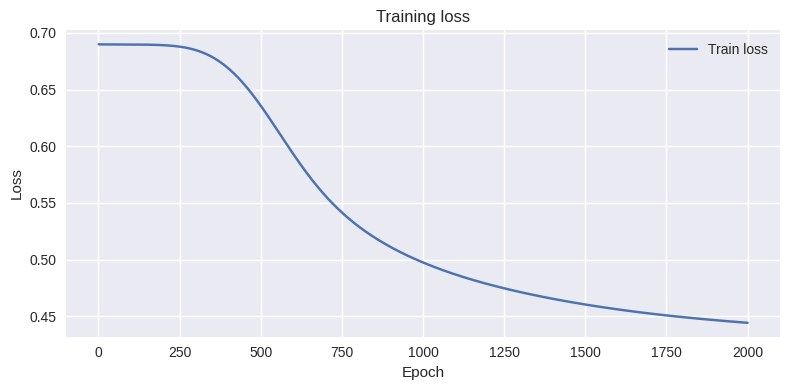

Neural FCA (New) F1: 0.8000
CPU times: user 6.07 s, sys: 42.9 ms, total: 6.11 s
Wall time: 6.17 s


In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000, plot_loss=True)

pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (New) F1: {f1_fca_base:.4f}")

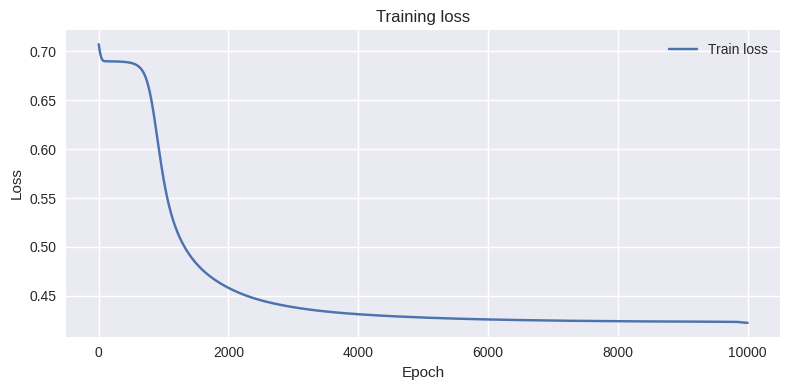

Neural FCA (New) F1: 0.8000
CPU times: user 29.8 s, sys: 187 ms, total: 30 s
Wall time: 30.3 s


In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=10000, plot_loss=True)

pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (New) F1: {f1_fca_base:.4f}")

In [ ]:
subset_size = 60
n_concepts = 15
n_epochs = 2000
n_splits = 5
random_state = 42

skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state
    )

fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    print(f"\nFold {fold}")

    X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    X_tr_bin = preprocessor.fit_transform(X_tr_raw)
    X_val_bin  = preprocessor.transform(X_val_raw)

    feature_names_cv = preprocessor.get_feature_names_out()

    X_tr_full = pd.DataFrame(
        X_tr_bin,
        columns=feature_names_cv,
        index=X_tr_raw.index
    ).astype(bool)

    X_val_full = pd.DataFrame(
        X_val_bin,
        columns=feature_names_cv,
        index=X_val_raw.index
    ).astype(bool)

    corrs_cv = {}
    y_arr = y_tr.to_numpy()

    for col in X_tr_full.columns:
        x = X_tr_full[col].astype(int).to_numpy()
        if x.std() == 0:
            corrs_cv[col] = 0.0
        else:
            c = np.corrcoef(x, y_arr)[0, 1]
            corrs_cv[col] = abs(c)

    sorted_attrs_cv = sorted(corrs_cv.keys(), key=lambda c: corrs_cv[c], reverse=True)

    attr_subset_size = min(10, len(sorted_attrs_cv))
    attrs_fca_cv = sorted_attrs_cv[:attr_subset_size]

    X_tr = X_tr_full[attrs_fca_cv]
    X_val  = X_val_full[attrs_fca_cv]

    X_fca = X_tr.sample(
        n=min(subset_size, len(X_tr)),
        replace=False,
        random_state=random_state
    )
    y_fca = y_tr.loc[X_fca.index]

    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L_cv = ConceptLattice.from_context(K_train, is_monotone=True)
    print(f"Lattice size: {len(L_cv)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L_cv))

    for i, c in enumerate(L_cv):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts_cv = concept_f1.argsort()[::-1][:n_concepts].tolist()
    print(f"Top {n_concepts} concepts: {best_concepts_cv}")

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L_cv,
        best_concepts_indices=best_concepts_cv,
        targets=tuple(sorted(set(y_tr)))
    )

    cn.fit(X_tr, y_tr, n_epochs=n_epochs)

    pred_prob = cn.predict_proba(X_val).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)

    fold_f1 = f1_score(y_val, pred_class)
    fold_scores.append(fold_f1)
    print(f"Fold {fold} F1: {fold_f1:.4f}")

mean_f1 = np.mean(fold_scores)
std_f1 = np.std(fold_scores)
print(f"\nNeural FCA (New) CV ({n_splits}-fold) F1: {mean_f1:.4f} ± {std_f1:.4f}")


Fold 1
Lattice size: 151
Top 15 concepts: [17, 11, 4, 7, 19, 16, 32, 26, 24, 25, 9, 18, 37, 38, 36]
Fold 1 F1: 0.8475

Fold 2
Lattice size: 196
Top 15 concepts: [12, 28, 26, 14, 13, 22, 19, 11, 36, 35, 21, 42, 41, 9, 27]
Fold 2 F1: 0.8302

Fold 3
Lattice size: 194
Top 15 concepts: [25, 17, 29, 11, 20, 16, 41, 18, 15, 30, 26, 34, 28, 23, 24]
Fold 3 F1: 0.7170

Fold 4
Lattice size: 294
Top 15 concepts: [18, 51, 53, 12, 45, 40, 85, 33, 32, 65, 26, 49, 17, 94, 75]
Fold 4 F1: 0.8235

Fold 5
Lattice size: 201
Top 15 concepts: [9, 15, 7, 19, 33, 26, 4, 23, 43, 17, 16, 32, 35, 20, 38]
Fold 5 F1: 0.8085

Neural FCA (New) CV (5-fold) F1: 0.8053 ± 0.0459


In [ ]:
subset_size = 60
n_concepts = 15
n_epochs = 2000
n_splits = 5
random_state = 42

fold_scores = []

best_val = 0
best_test = 0

X_val = X_train.sample(
        n=80,
        replace=False,
        random_state=random_state
    )
y_val = y_train.loc[X_val.index]

mask_other = ~X_train.index.isin(X_val.index)
X_other = X_train.loc[mask_other]
y_other = y_train.loc[mask_other]

for i in range(1, 10):
    print(f"\nFold {i}")

    X_fca = X_other.sample(
        n=min(subset_size, len(X_other)),
        replace=False,
    )
    y_fca = y_train.loc[X_fca.index]

    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L_cv = ConceptLattice.from_context(K_train, is_monotone=True)
    print(f"Lattice size: {len(L_cv)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L_cv))

    for i, c in enumerate(L_cv):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts_cv = concept_f1.argsort()[::-1][:n_concepts].tolist()
    print(f"Top {n_concepts} concepts: {best_concepts_cv}")

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L_cv,
        best_concepts_indices=best_concepts_cv,
        targets=tuple(sorted(set(y_train)))
    )

    cn.fit(X_train, y_train, n_epochs=n_epochs)

    pred_prob = cn.predict_proba(X_val).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)

    fold_f1 = f1_score(y_val, pred_class)

    pred_prob = cn.predict_proba(X_test).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)

    f1_fca_test = f1_score(y_test, pred_class)

    print(f"Fold {i} F1: {fold_f1:.4f} | test: {f1_fca_test}")

    if fold_f1 > best_val:
        best_val = fold_f1
        best_test = f1_fca_test


results_fca['Neural FCA (New) CV'] = best_test
print(f"\nNeural FCA (New) CV F1: {best_test}")


Fold 1
Lattice size: 239
Top 15 concepts: [24, 65, 19, 21, 84, 83, 43, 62, 31, 109, 38, 56, 125, 124, 123]
Fold 238 F1: 0.7869 | test: 0.7843137254901961

Fold 2
Lattice size: 260
Top 15 concepts: [24, 18, 38, 22, 5, 44, 39, 35, 61, 32, 46, 70, 72, 67, 28]
Fold 259 F1: 0.8000 | test: 0.8

Fold 3
Lattice size: 211
Top 15 concepts: [9, 17, 25, 26, 16, 30, 29, 51, 50, 41, 31, 19, 46, 68, 62]
Fold 210 F1: 0.7869 | test: 0.8076923076923077

Fold 4
Lattice size: 265
Top 15 concepts: [17, 24, 38, 23, 21, 7, 48, 32, 35, 57, 55, 20, 11, 3, 47]
Fold 264 F1: 0.7797 | test: 0.8

Fold 5
Lattice size: 255
Top 15 concepts: [17, 22, 6, 28, 27, 30, 38, 39, 46, 18, 19, 4, 34, 53, 52]
Fold 254 F1: 0.7797 | test: 0.8

Fold 6
Lattice size: 211
Top 15 concepts: [25, 19, 7, 6, 31, 21, 18, 42, 26, 33, 45, 36, 37, 20, 22]
Fold 210 F1: 0.8000 | test: 0.8235294117647058

Fold 7
Lattice size: 273
Top 15 concepts: [24, 18, 25, 30, 26, 6, 28, 44, 31, 22, 20, 49, 50, 27, 36]
Fold 272 F1: 0.7742 | test: 0.8301886792

In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000, use_batch_norm = True)

pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (norm) F1: {f1_fca_base:.4f}")

results_fca['Neural FCA (norm)'] = f1_fca_base

Neural FCA (norm) F1: 0.8077
CPU times: user 8.21 s, sys: 47.8 ms, total: 8.26 s
Wall time: 8.36 s


In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000, use_dropout = True, dropout_rate=0.1)

pred_prob = cn.predict_proba(X_test).detach().numpy()
pred_class = np.argmax(pred_prob, axis=1)

f1_fca_base = f1_score(y_test, pred_class)
print(f"Neural FCA (dropout) F1: {f1_fca_base:.4f}")

results_fca['Neural FCA (dropout)'] = f1_fca_base

Neural FCA (dropout) F1: 0.8235
CPU times: user 6.13 s, sys: 23 ms, total: 6.16 s
Wall time: 6.17 s


## 4. First results and Visualization

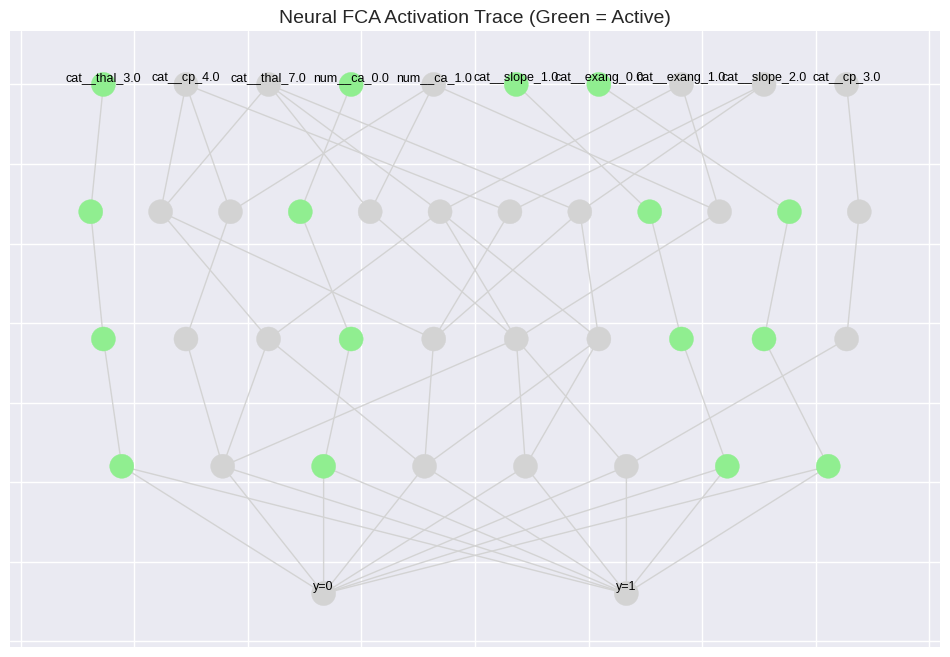

In [ ]:
sample_idx = 0
sample_descr = set(X_test.iloc[sample_idx][X_test.iloc[sample_idx]].index)
traced = cn.trace_description(frozenset(sample_descr), include_targets=False)

fig, ax = plt.subplots(figsize=(12, 8))
vis = LineVizNx(node_label_font_size=9, node_label_func=lambda el_i, P: nl.neuron_label_func(el_i, P, set(cn.attributes))+'\n')
vis.draw_poset(
    cn.poset, ax=ax,
    flg_node_indices=False,
    node_color=['lightgreen' if el_i in traced else 'lightgray' for el_i in range(len(cn.poset))]
)
plt.title("Neural FCA Activation Trace (Green = Active)", fontsize=14)
plt.show()

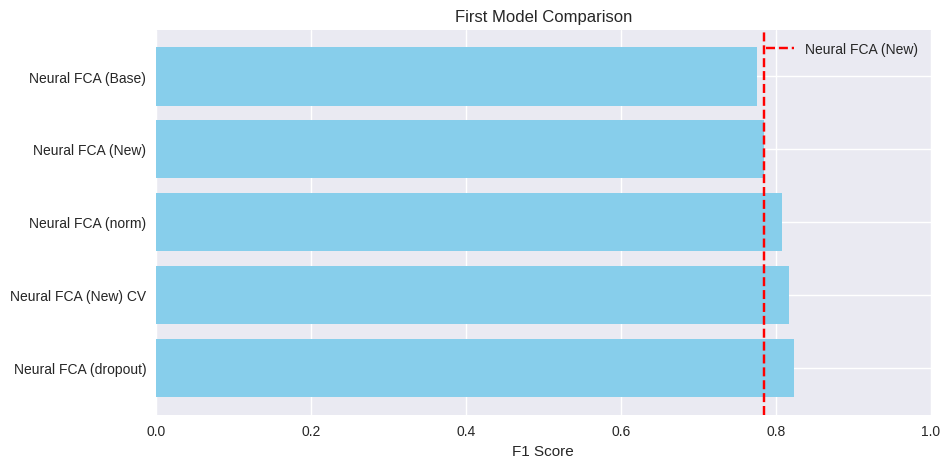

                  Model  F1 Score
3  Neural FCA (dropout)  0.823529
4   Neural FCA (New) CV  0.816327
2     Neural FCA (norm)  0.807692
1      Neural FCA (New)  0.784314
0     Neural FCA (Base)  0.775510


In [ ]:
results['Neural FCA (Base)'] = results_fca['Neural FCA (Base)']
results['Neural FCA (New)'] = results_fca['Neural FCA (New)']
results['Neural FCA (norm)'] = results_fca['Neural FCA (norm)']
results['Neural FCA (dropout)'] = results_fca['Neural FCA (dropout)']
results['Neural FCA (New) CV'] = results_fca['Neural FCA (New) CV']

results_df = pd.DataFrame(list(results.items()), columns=['Model', 'F1 Score'])
results_df = results_df.sort_values(by='F1 Score', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(results_df['Model'], results_df['F1 Score'], color='skyblue')
plt.xlabel('F1 Score')
plt.title('First Model Comparison')
plt.xlim(0, 1.0)
plt.axvline(results_fca['Neural FCA (New)'], color='red', linestyle='--', label='Neural FCA (New)')
plt.legend()
plt.show()
print(results_df)

## 5. Improvements

### Pipeline

In [ ]:
def fit_with_regularization(
    model_net,
    X_df,
    y_series,
    n_epochs: int = 2000,
    lr: float = 0.001,
    l1_lambda: float = 0.0001,
    batch_size: int = 64,
    early_stopping_patience: int = 50,
    verbose: bool = True
):
    if model_net.network is None:
        model_net.fit(X_df, y_series, n_epochs=0)

    from sklearn.model_selection import train_test_split

    X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
        X_df, y_series, test_size=0.15, random_state=42, stratify=y_series
    )

    X_train_tensor = torch.from_numpy(X_train_split[list(model_net.attributes)].values.astype("float32"))
    y_train_tensor = torch.from_numpy(y_train_split.values.astype("int64"))

    X_val_tensor = torch.from_numpy(X_val_split[list(model_net.attributes)].values.astype("float32"))
    y_val_tensor = torch.from_numpy(y_val_split.values.astype("int64"))

    from torch.utils.data import TensorDataset, DataLoader

    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    optimizer = torch.optim.AdamW(model_net.network.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=20
    )
    loss_fn = torch.nn.CrossEntropyLoss()

    best_val_loss = float('inf')
    patience_counter = 0
    best_state = None

    for epoch in range(n_epochs):
        model_net.network.train()
        train_loss = 0.0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()

            y_pred = model_net.network(X_batch)
            ce_loss = loss_fn(y_pred, y_batch)

            l1_loss = 0.0
            for name, param in model_net.network.named_parameters():
                if 'weight' in name:
                    l1_loss = l1_loss + param.abs().sum()

            total_loss = ce_loss + l1_lambda * l1_loss
            total_loss.backward()

            torch.nn.utils.clip_grad_norm_(model_net.network.parameters(), max_norm=1.0)

            optimizer.step()
            train_loss += total_loss.item()

        model_net.network.eval()
        with torch.no_grad():
            y_val_pred = model_net.network(X_val_tensor)
            val_loss = loss_fn(y_val_pred, y_val_tensor).item()

        old_lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_loss)
        new_lr = optimizer.param_groups[0]['lr']

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_state = {k: v.cpu().clone() for k, v in model_net.network.state_dict().items()}
        else:
            patience_counter += 1

        if verbose and (epoch + 1) % 100 == 0:
            avg_train_loss = train_loss / len(train_loader)
            print(f"Epoch {epoch+1}/{n_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | LR: {new_lr:.6f}")
            if old_lr != new_lr:
                print(f"  -> Learning rate reduced to {new_lr:.6f}")

        if patience_counter >= early_stopping_patience:
            if verbose:
                print(f"Early stopping at epoch {epoch+1}")
            break

    if best_state is not None:
        model_net.network.load_state_dict(best_state)
        if verbose:
            print(f"Restored best model with val_loss: {best_val_loss:.4f}")

    model_net.network.eval()
    return model_net

In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000)

cn_init1 = copy.deepcopy(cn)
cn_init2 = copy.deepcopy(cn)

CPU times: user 5.97 s, sys: 38.8 ms, total: 6.01 s
Wall time: 6.11 s


In [ ]:
# Option 1
cn_improved1 = fit_with_regularization(
    cn_init1, X_train, y_train,
    n_epochs=2000,
    lr=0.001,
    l1_lambda=0.0001,
    batch_size=64,
    early_stopping_patience=50,
    verbose=True
)

pred_prob_imp = cn_improved1.predict_proba(X_test).detach().numpy()
pred_class_imp = np.argmax(pred_prob_imp, axis=1)
f1_fca_imp = f1_score(y_test, pred_class_imp, average='weighted')

print(f"\nNeural FCA (Improved) F1: {f1_fca_imp:.4f}")
if 'Neural FCA' in results:
    baseline_f1 = results['Neural FCA']
    print(f"Baseline F1: {baseline_f1:.4f}")
    print(f"Improvement: {(f1_fca_imp - baseline_f1):.4f} ({((f1_fca_imp/baseline_f1 - 1) * 100):.2f}%)")

results_fca['Neural FCA (Imp 1)'] = f1_fca_imp

Early stopping at epoch 51
Restored best model with val_loss: 0.4691

Neural FCA (Improved) F1: 0.8318


In [ ]:
# Option 2: No regularization + very low LR (fine-tuning)
cn_improved2 = fit_with_regularization(
    cn_init2, X_train, y_train,
    n_epochs=1000,
    lr=0.0001,
    l1_lambda=0.0,
    batch_size=128,
    early_stopping_patience=30,
    verbose=True
)

pred_prob_imp = cn_improved2.predict_proba(X_test).detach().numpy()
pred_class_imp = np.argmax(pred_prob_imp, axis=1)
f1_fca_imp = f1_score(y_test, pred_class_imp, average='weighted')

print(f"\nNeural FCA (Improved) F1: {f1_fca_imp:.4f}")
if 'Neural FCA' in results:
    baseline_f1 = results['Neural FCA']
    print(f"Baseline F1: {baseline_f1:.4f}")
    print(f"Improvement: {(f1_fca_imp - baseline_f1):.4f} ({((f1_fca_imp/baseline_f1 - 1) * 100):.2f}%)")

results_fca['Neural FCA (Imp 2)'] = f1_fca_imp


Early stopping at epoch 31
Restored best model with val_loss: 0.4694

Neural FCA (Improved) F1: 0.8318


In [ ]:
subset_size = 60
n_concepts = 15
n_epochs = 2000
n_splits = 5
random_state = 42

fold_scores = []

cn_best = None
best_val = 0
best_test = 0

X_val = X_train.sample(
        n=80,
        replace=False,
        random_state=random_state
    )
y_val = y_train.loc[X_val.index]

mask_other = ~X_train.index.isin(X_val.index)
X_other = X_train.loc[mask_other]
y_other = y_train.loc[mask_other]

for i in range(1, 10):
    print(f"\n=== Fold {i} ===")
    X_fca = X_other.sample(
        n=min(subset_size, len(X_other)),
        replace=False,
    )
    y_fca = y_train.loc[X_fca.index]

    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L_cv = ConceptLattice.from_context(K_train, is_monotone=True)
    print(f"Lattice size: {len(L_cv)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L_cv))

    for i, c in enumerate(L_cv):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts_cv = concept_f1.argsort()[::-1][:n_concepts].tolist()
    print(f"Top {n_concepts} concepts: {best_concepts_cv}")

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L_cv,
        best_concepts_indices=best_concepts_cv,
        targets=tuple(sorted(set(y_train)))
    )

    cn.fit(X_train, y_train, n_epochs=n_epochs)

    pred_prob = cn.predict_proba(X_val).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)

    fold_f1 = f1_score(y_val, pred_class)

    pred_prob = cn.predict_proba(X_test).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)

    f1_fca_test = f1_score(y_test, pred_class)


    print(f"Fold {i} F1: {fold_f1:.4f} | test: {f1_fca_test}")

    if fold_f1 > best_val:
        best_val = fold_f1
        best_test = f1_fca_test
        cn_best = cn


cn_improved3 = fit_with_regularization(
    cn_best, X_train, y_train,
    n_epochs=1000,
    lr=0.0001,
    l1_lambda=0.0,
    batch_size=128,
    early_stopping_patience=30,
    verbose=True
)

pred_prob_imp = cn_improved3.predict_proba(X_test).detach().numpy()
pred_class_imp = np.argmax(pred_prob_imp, axis=1)
f1_fca_imp = f1_score(y_test, pred_class_imp, average='weighted')

print(f"\nNeural FCA (Improved) F1: {f1_fca_imp:.4f}")
if 'Neural FCA' in results:
    baseline_f1 = results['Neural FCA']
    print(f"Baseline F1: {baseline_f1:.4f}")
    print(f"Improvement: {(f1_fca_imp - baseline_f1):.4f} ({((f1_fca_imp/baseline_f1 - 1) * 100):.2f}%)")

results_fca['Neural FCA (CV + Imp 2)'] = f1_fca_imp


=== Fold 1 ===
Lattice size: 206
Top 15 concepts: [10, 33, 31, 20, 37, 7, 21, 17, 34, 32, 48, 44, 54, 53, 50]
Fold 205 F1: 0.8000 | test: 0.8

=== Fold 2 ===
Lattice size: 216
Top 15 concepts: [19, 14, 41, 16, 28, 20, 59, 51, 42, 69, 68, 29, 55, 21, 82]
Fold 215 F1: 0.7797 | test: 0.75

=== Fold 3 ===
Lattice size: 269
Top 15 concepts: [32, 62, 53, 42, 64, 65, 89, 73, 28, 56, 54, 105, 101, 107, 108]
Fold 268 F1: 0.8000 | test: 0.7755102040816326

=== Fold 4 ===
Lattice size: 199
Top 15 concepts: [16, 12, 22, 23, 7, 13, 3, 18, 8, 27, 15, 17, 5, 33, 19]
Fold 198 F1: 0.8136 | test: 0.8163265306122449

=== Fold 5 ===
Lattice size: 177
Top 15 concepts: [33, 25, 24, 16, 7, 41, 18, 34, 26, 27, 38, 36, 15, 42, 55]
Fold 176 F1: 0.7797 | test: 0.8

=== Fold 6 ===
Lattice size: 255
Top 15 concepts: [17, 38, 32, 42, 16, 53, 46, 40, 59, 31, 14, 44, 26, 28, 29]
Fold 254 F1: 0.8000 | test: 0.8

=== Fold 7 ===
Lattice size: 214
Top 15 concepts: [18, 10, 3, 31, 30, 22, 19, 20, 27, 11, 43, 44, 34, 26, 

In [ ]:
%%time
cn = nl_new.ConceptNetwork.from_lattice(
    lattice=L,
    best_concepts_indices=best_concepts,
    targets=tuple(sorted(set(y_train)))
)

cn.fit(X_train, y_train, n_epochs=2000, use_batch_norm = True)

# Option 2: No regularization + very low LR (fine-tuning)
cn_improved = fit_with_regularization(
    cn, X_train, y_train,
    n_epochs=1000,
    lr=0.0001,
    l1_lambda=0.0,
    batch_size=128,
    early_stopping_patience=30,
    verbose=True
)

pred_prob_imp = cn_improved.predict_proba(X_test).detach().numpy()
pred_class_imp = np.argmax(pred_prob_imp, axis=1)
f1_fca_imp = f1_score(y_test, pred_class_imp, average='weighted')

print(f"\nNeural FCA (Improved) F1: {f1_fca_imp:.4f}")
if 'Neural FCA' in results:
    baseline_f1 = results['Neural FCA']
    print(f"Baseline F1: {baseline_f1:.4f}")
    print(f"Improvement: {(f1_fca_imp - baseline_f1):.4f} ({((f1_fca_imp/baseline_f1 - 1) * 100):.2f}%)")

results_fca['Neural FCA (Imp 2 norm)'] = f1_fca_imp


Early stopping at epoch 31
Restored best model with val_loss: 0.4670

Neural FCA (Improved) F1: 0.8305
CPU times: user 10.6 s, sys: 41.8 ms, total: 10.6 s
Wall time: 10.8 s


### Fit again Baselines

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(kernel='rbf'),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss')
}

results_all = {}

for name, model in models.items():
    model.fit(X_train_full.astype(int), y_train)
    preds = model.predict(X_test_full.astype(int))
    f1 = f1_score(y_test, preds)
    results_all[name] = f1
    print(f"{name:20}: F1={f1:.4f}")

Logistic Regression : F1=0.7308
Random Forest       : F1=0.8364
SVM                 : F1=0.8148
XGBoost             : F1=0.8148


### Bagging

In [ ]:
import numpy as np
from sklearn.metrics import f1_score

n_bootstraps = 20
subset_size = 60
n_concepts = 15
attr_subset_size = 10

bootstraps = []
trained_models = []

for boot_idx in range(n_bootstraps):
    print(f"Bootstrap {boot_idx + 1}")

    n_samples = len(y_train)
    attr_bootstrap_indices = np.random.choice(n_samples, size=n_samples, replace=True)

    y_boot_attr = y_train.iloc[attr_bootstrap_indices].to_numpy()
    X_boot_attr = X_train_full.iloc[attr_bootstrap_indices]

    corrs = {}
    for col in X_train_full.columns:
        x = X_boot_attr[col].astype(int).to_numpy()
        if x.std() == 0:
            corrs[col] = 0.0
        else:
            c = np.corrcoef(x, y_boot_attr)[0, 1]
            corrs[col] = abs(c)

    sorted_attrs = sorted(corrs.keys(), key=lambda c: corrs[c], reverse=True)
    attrs_fca = sorted_attrs[:attr_subset_size]

    X_train_boot = X_train_full[attrs_fca]
    X_test_boot = X_test_full[attrs_fca]

    X_fca = X_train_boot.sample(
        n=min(subset_size, len(X_train_boot)),
        replace=True,
        random_state=42 + boot_idx
    )
    y_fca = y_train.loc[X_fca.index]

    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L = ConceptLattice.from_context(K_train, is_monotone=True)

    print(f"  Lattice Size: {len(L)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L))

    for i, c in enumerate(L):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds, zero_division=0)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts = concept_f1.argsort()[::-1][:n_concepts].tolist()

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L,
        best_concepts_indices=best_concepts,
        targets=tuple(sorted(set(y_train)))
    )

    cn.fit(X_train_boot, y_train, n_epochs=2000)

    bootstrap_info = {
        'iteration': boot_idx,
        'attributes': attrs_fca,
        'correlations': {a: corrs[a] for a in attrs_fca},
        'lattice': L,
        'best_concepts': best_concepts,
        'model': cn,
        'X_test_boot': X_test_boot
    }

    bootstraps.append(bootstrap_info)
    trained_models.append(cn)

    pred_prob_boot = cn.predict_proba(X_test_boot).detach().numpy()
    pred_class_boot = np.argmax(pred_prob_boot, axis=1)
    f1_boot = f1_score(y_test, pred_class_boot)
    print(f"F1 on this bootstrap: {f1_boot:.4f}")


all_predictions_proba = []

for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    all_predictions_proba.append(pred_prob)

all_predictions_proba = np.array(all_predictions_proba)
mean_pred_proba = np.mean(all_predictions_proba, axis=0)

pred_class_bagging = np.argmax(mean_pred_proba, axis=1)

f1_bagging = f1_score(y_test, pred_class_bagging)

print(f"\nResults:")
print(f"Number of models: {n_bootstraps}")
print(f"F1 (Bagging): {f1_bagging:.4f}")

individual_f1_scores = []
for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)
    f1 = f1_score(y_test, pred_class)
    individual_f1_scores.append(f1)

print(f"Mean: {np.mean(individual_f1_scores):.4f}")
print(f"Min: {np.min(individual_f1_scores):.4f}")
print(f"Max: {np.max(individual_f1_scores):.4f}")
print(f"Std: {np.std(individual_f1_scores):.4f}")

results['Neural FCA (Bagging)'] = f1_bagging

attr_frequency = {}
for boot in bootstraps:
    for attr in boot['attributes']:
        attr_frequency[attr] = attr_frequency.get(attr, 0) + 1

top_stable_attrs = sorted(attr_frequency.items(), key=lambda x: x[1], reverse=True)

std_predictions = np.std(all_predictions_proba[:, :, 1], axis=0)
print(f"Mean probability dispersion: {np.mean(std_predictions):.4f}")
print(f"Max dispersion: {np.max(std_predictions):.4f}")

uncertain_indices = np.argsort(std_predictions)[-5:]

Bootstrap 1
  Lattice Size: 181
F1 on this bootstrap: 0.7755
Bootstrap 2
  Lattice Size: 278
F1 on this bootstrap: 0.8000
Bootstrap 3
  Lattice Size: 208
F1 on this bootstrap: 0.8000
Bootstrap 4
  Lattice Size: 246
F1 on this bootstrap: 0.8235
Bootstrap 5
  Lattice Size: 269
F1 on this bootstrap: 0.8000
Bootstrap 6
  Lattice Size: 248
F1 on this bootstrap: 0.8235
Bootstrap 7
  Lattice Size: 203
F1 on this bootstrap: 0.8235
Bootstrap 8
  Lattice Size: 238
F1 on this bootstrap: 0.7755
Bootstrap 9
  Lattice Size: 260
F1 on this bootstrap: 0.7755
Bootstrap 10
  Lattice Size: 230
F1 on this bootstrap: 0.8000
Bootstrap 11
  Lattice Size: 229
F1 on this bootstrap: 0.8000
Bootstrap 12
  Lattice Size: 207
F1 on this bootstrap: 0.8235
Bootstrap 13
  Lattice Size: 181
F1 on this bootstrap: 0.8000
Bootstrap 14
  Lattice Size: 284
F1 on this bootstrap: 0.8333
Bootstrap 15
  Lattice Size: 232
F1 on this bootstrap: 0.7917
Bootstrap 16
  Lattice Size: 158
F1 on this bootstrap: 0.7755
Bootstrap 17
  La

In [ ]:
subset_size = 60
n_concepts = 15
attr_subset_size = 10
n_epochs = 2000
n_bootstraps = 20
n_splits = 5
random_state = 42

skf = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=random_state
)

fold_scores = []

rng = np.random.RandomState(random_state)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    print(f"Fold {fold}")

    X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    X_tr_bin = preprocessor.fit_transform(X_tr_raw)
    X_val_bin = preprocessor.transform(X_val_raw)

    feature_names_c = preprocessor.get_feature_names_out()

    X_tr_full = pd.DataFrame(
        X_tr_bin,
        columns=feature_names_c,
        index=X_tr_raw.index
    ).astype(bool)

    X_val_full = pd.DataFrame(
        X_val_bin,
        columns=feature_names_c,
        index=X_val_raw.index
    ).astype(bool)

    all_predictions_proba = []

    for boot_idx in range(n_bootstraps):
        n_samples = len(y_tr)
        attr_bootstrap_indices = rng.choice(
            n_samples, size=n_samples, replace=True
        )

        y_boot_attr = y_tr.iloc[attr_bootstrap_indices].to_numpy()
        X_boot_attr = X_tr_full.iloc[attr_bootstrap_indices]

        corrs_cv = {}
        for col in X_tr_full.columns:
            x = X_boot_attr[col].astype(int).to_numpy()
            if x.std() == 0:
                corrs_cv[col] = 0.0
            else:
                c = np.corrcoef(x, y_boot_attr)[0, 1]
                corrs_cv[col] = abs(c)

        sorted_attrs_cv = sorted(corrs_cv.keys(), key=lambda c: corrs_cv[c], reverse=True)
        attrs_fca_cv = sorted_attrs_cv[:attr_subset_size]

        X_train_boot = X_tr_full[attrs_fca_cv]
        X_val_boot = X_val_full[attrs_fca_cv]

        X_fca = X_train_boot.sample(
            n=min(subset_size, len(X_train_boot)),
            replace=True,
            random_state=random_state + boot_idx
        )
        y_fca = y_tr.loc[X_fca.index]

        X_fca_ctx = X_fca.copy()
        X_fca_ctx.index = X_fca_ctx.index.astype(str)

        K_train = FormalContext.from_pandas(X_fca_ctx)
        L_cv = ConceptLattice.from_context(K_train, is_monotone=True)

        y_fca_arr = y_fca.to_numpy()
        concept_f1 = np.zeros(len(L_cv))

        for i, c in enumerate(L_cv):
            y_preds = np.zeros_like(y_fca_arr)
            y_preds[list(c.extent_i)] = 1

            score = f1_score(y_fca_arr, y_preds, zero_division=0)
            c.measures['f1_score'] = score
            concept_f1[i] = score

        best_concepts_cv = concept_f1.argsort()[::-1][:n_concepts].tolist()

        cn = nl_new.ConceptNetwork.from_lattice(
            lattice=L_cv,
            best_concepts_indices=best_concepts_cv,
            targets=tuple(sorted(set(y_tr)))
        )

        cn.fit(X_train_boot, y_tr, n_epochs=n_epochs)

        pred_prob_boot = cn.predict_proba(X_val_boot).detach().numpy()
        all_predictions_proba.append(pred_prob_boot)

    all_predictions_proba = np.array(all_predictions_proba)  # (n_bootstraps, n_val, n_classes)
    mean_pred_proba = np.mean(all_predictions_proba, axis=0)
    pred_class_bagging = np.argmax(mean_pred_proba, axis=1)

    fold_f1 = f1_score(y_val, pred_class_bagging)
    fold_scores.append(fold_f1)
    print(f"Fold {fold} Bagging F1: {fold_f1:.4f}")

mean_f1 = np.mean(fold_scores)
std_f1 = np.std(fold_scores)

Fold 1
Fold 1 Bagging F1: 0.8621
Fold 2
Fold 2 Bagging F1: 0.8727
Fold 3
Fold 3 Bagging F1: 0.7273
Fold 4
Fold 4 Bagging F1: 0.8462
Fold 5
Fold 5 Bagging F1: 0.7917


In [ ]:
import numpy as np
from sklearn.metrics import f1_score


n_bootstraps = 10
subset_size = 60
n_concepts = 15
attr_subset_size = 10

bootstraps = []
trained_models = []

for boot_idx in range(n_bootstraps):
    print(f"Bootstrap {boot_idx + 1}/{n_bootstraps}")

    n_samples = len(y_train)
    attr_bootstrap_indices = np.random.choice(n_samples, size=n_samples, replace=True)

    y_boot_attr = y_train.iloc[attr_bootstrap_indices].to_numpy()
    X_boot_attr = X_train_full.iloc[attr_bootstrap_indices]

    corrs = {}
    for col in X_train_full.columns:
        x = X_boot_attr[col].astype(int).to_numpy()
        if x.std() == 0:
            corrs[col] = 0.0
        else:
            c = np.corrcoef(x, y_boot_attr)[0, 1]
            corrs[col] = abs(c)

    sorted_attrs = sorted(corrs.keys(), key=lambda c: corrs[c], reverse=True)
    attrs_fca = sorted_attrs[:attr_subset_size]

    X_train_boot = X_train_full[attrs_fca]
    X_test_boot = X_test_full[attrs_fca]

    X_fca = X_train_boot.sample(
        n=min(subset_size, len(X_train_boot)),
        replace=True,
        random_state=42 + boot_idx
    )
    y_fca = y_train.loc[X_fca.index]


    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L = ConceptLattice.from_context(K_train, is_monotone=True)

    print(f"  Lattice Size: {len(L)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L))

    for i, c in enumerate(L):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds, zero_division=0)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts = concept_f1.argsort()[::-1][:n_concepts].tolist()

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L,
        best_concepts_indices=best_concepts,
        targets=tuple(sorted(set(y_train)))
    )

    cn.fit(X_train_boot, y_train, n_epochs=2000, use_batch_norm = True)

    bootstrap_info = {
        'iteration': boot_idx,
        'attributes': attrs_fca,
        'correlations': {a: corrs[a] for a in attrs_fca},
        'lattice': L,
        'best_concepts': best_concepts,
        'model': cn,
        'X_test_boot': X_test_boot
    }

    bootstraps.append(bootstrap_info)
    trained_models.append(cn)

    pred_prob_boot = cn.predict_proba(X_test_boot).detach().numpy()
    pred_class_boot = np.argmax(pred_prob_boot, axis=1)
    f1_boot = f1_score(y_test, pred_class_boot)
    print(f"F1 on this bootstrap: {f1_boot:.4f}")


all_predictions_proba = []

for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    all_predictions_proba.append(pred_prob)

all_predictions_proba = np.array(all_predictions_proba)
mean_pred_proba = np.mean(all_predictions_proba, axis=0)

pred_class_bagging = np.argmax(mean_pred_proba, axis=1)

f1_bagging = f1_score(y_test, pred_class_bagging)

print(f"F1 (Bagging): {f1_bagging:.4f}")

individual_f1_scores = []
for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)
    f1 = f1_score(y_test, pred_class)
    individual_f1_scores.append(f1)

print(f"Mean: {np.mean(individual_f1_scores):.4f}")
print(f"Min: {np.min(individual_f1_scores):.4f}")
print(f"Max: {np.max(individual_f1_scores):.4f}")
print(f"Std: {np.std(individual_f1_scores):.4f}")

results_fca['Neural FCA (Bagging ++ norm)'] = f1_bagging

attr_frequency = {}
for boot in bootstraps:
    for attr in boot['attributes']:
        attr_frequency[attr] = attr_frequency.get(attr, 0) + 1

top_stable_attrs = sorted(attr_frequency.items(), key=lambda x: x[1], reverse=True)

std_predictions = np.std(all_predictions_proba[:, :, 1], axis=0)
print(f"Mean probability dispersion: {np.mean(std_predictions):.4f}")
print(f"Max dispersion: {np.max(std_predictions):.4f}")

uncertain_indices = np.argsort(std_predictions)[-5:]

Bootstrap 1/10
  Lattice Size: 192
F1 on this bootstrap: 0.7925
Bootstrap 2/10
  Lattice Size: 306
F1 on this bootstrap: 0.7925
Bootstrap 3/10
  Lattice Size: 194
F1 on this bootstrap: 0.8214
Bootstrap 4/10
  Lattice Size: 246
F1 on this bootstrap: 0.4444
Bootstrap 5/10
  Lattice Size: 238
F1 on this bootstrap: 0.8000
Bootstrap 6/10
  Lattice Size: 224
F1 on this bootstrap: 0.8077
Bootstrap 7/10
  Lattice Size: 306
F1 on this bootstrap: 0.8000
Bootstrap 8/10
  Lattice Size: 217
F1 on this bootstrap: 0.8077
Bootstrap 9/10
  Lattice Size: 236
F1 on this bootstrap: 0.7755
Bootstrap 10/10
  Lattice Size: 238
F1 on this bootstrap: 0.7556
F1 (Bagging): 0.8000
Mean: 0.7597
Min: 0.4444
Max: 0.8214
Std: 0.1065
Mean probability dispersion: 0.1234
Max dispersion: 0.3191


In [ ]:
import numpy as np
from sklearn.metrics import f1_score


n_bootstraps = 10
subset_size = 60
n_concepts = 15
attr_subset_size = 10

bootstraps = []
trained_models = []

for boot_idx in range(n_bootstraps):
    print(f"Bootstrap {boot_idx + 1}")

    n_samples = len(y_train)
    attr_bootstrap_indices = np.random.choice(n_samples, size=n_samples, replace=True)

    y_boot_attr = y_train.iloc[attr_bootstrap_indices].to_numpy()
    X_boot_attr = X_train_full.iloc[attr_bootstrap_indices]

    corrs = {}
    for col in X_train_full.columns:
        x = X_boot_attr[col].astype(int).to_numpy()
        if x.std() == 0:
            corrs[col] = 0.0
        else:
            c = np.corrcoef(x, y_boot_attr)[0, 1]
            corrs[col] = abs(c)

    sorted_attrs = sorted(corrs.keys(), key=lambda c: corrs[c], reverse=True)
    attrs_fca = sorted_attrs[:attr_subset_size]

    X_train_boot = X_train_full[attrs_fca]
    X_test_boot = X_test_full[attrs_fca]

    X_fca = X_train_boot.sample(
        n=min(subset_size, len(X_train_boot)),
        replace=True,
        random_state=42 + boot_idx
    )
    y_fca = y_train.loc[X_fca.index]

    X_fca_ctx = X_fca.copy()
    X_fca_ctx.index = X_fca_ctx.index.astype(str)

    K_train = FormalContext.from_pandas(X_fca_ctx)
    L = ConceptLattice.from_context(K_train, is_monotone=True)

    print(f"Lattice Size: {len(L)}")

    y_fca_arr = y_fca.to_numpy()
    concept_f1 = np.zeros(len(L))

    for i, c in enumerate(L):
        y_preds = np.zeros_like(y_fca_arr)
        y_preds[list(c.extent_i)] = 1

        score = f1_score(y_fca_arr, y_preds, zero_division=0)
        c.measures['f1_score'] = score
        concept_f1[i] = score

    best_concepts = concept_f1.argsort()[::-1][:n_concepts].tolist()

    cn = nl_new.ConceptNetwork.from_lattice(
        lattice=L,
        best_concepts_indices=best_concepts,
        targets=tuple(sorted(set(y_train)))
    )

    cn.fit(X_train_boot, y_train, n_epochs=2000, use_batch_norm = True)

    cn_improved = fit_with_regularization(
        cn, X_train_boot, y_train,
        n_epochs=1000,
        lr=0.0001,
        l1_lambda=0.0,
        batch_size=128,
        early_stopping_patience=30,
        verbose=True
    )

    bootstrap_info = {
        'iteration': boot_idx,
        'attributes': attrs_fca,
        'correlations': {a: corrs[a] for a in attrs_fca},
        'lattice': L,
        'best_concepts': best_concepts,
        'model': cn,
        'X_test_boot': X_test_boot
    }

    bootstraps.append(bootstrap_info)
    trained_models.append(cn)

    pred_prob_boot = cn_improved.predict_proba(X_test_boot).detach().numpy()
    pred_class_boot = np.argmax(pred_prob_boot, axis=1)
    f1_boot = f1_score(y_test, pred_class_boot)
    print(f"  F1 on this bootstrap: {f1_boot:.4f}")

all_predictions_proba = []

for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    all_predictions_proba.append(pred_prob)

all_predictions_proba = np.array(all_predictions_proba)
mean_pred_proba = np.mean(all_predictions_proba, axis=0)

pred_class_bagging = np.argmax(mean_pred_proba, axis=1)

f1_bagging = f1_score(y_test, pred_class_bagging)

print(f"\nResults:")
print(f"Number of models: {n_bootstraps}")
print(f"F1 (Bagging): {f1_bagging:.4f}")

individual_f1_scores = []
for boot_idx, boot_info in enumerate(bootstraps):
    cn = boot_info['model']
    X_test_boot = boot_info['X_test_boot']

    pred_prob = cn.predict_proba(X_test_boot).detach().numpy()
    pred_class = np.argmax(pred_prob, axis=1)
    f1 = f1_score(y_test, pred_class)
    individual_f1_scores.append(f1)

print(f"\nStatistics for individual models:")
print(f"Mean: {np.mean(individual_f1_scores):.4f}")
print(f"Min: {np.min(individual_f1_scores):.4f}")
print(f"Max: {np.max(individual_f1_scores):.4f}")
print(f"Std: {np.std(individual_f1_scores):.4f}")

results_fca['Neural FCA (Bagging + norm + imp)'] = f1_bagging

attr_frequency = {}
for boot in bootstraps:
    for attr in boot['attributes']:
        attr_frequency[attr] = attr_frequency.get(attr, 0) + 1

top_stable_attrs = sorted(attr_frequency.items(), key=lambda x: x[1], reverse=True)

std_predictions = np.std(all_predictions_proba[:, :, 1], axis=0)
print(f"Mean probability dispersion: {np.mean(std_predictions):.4f}")
print(f"Max dispersion: {np.max(std_predictions):.4f}")

uncertain_indices = np.argsort(std_predictions)[-5:]

Bootstrap 1
Lattice Size: 199
Early stopping at epoch 46
Restored best model with val_loss: 0.4497
  F1 on this bootstrap: 0.8235
Bootstrap 2
Lattice Size: 265
Early stopping at epoch 36
Restored best model with val_loss: 0.4318
  F1 on this bootstrap: 0.8000
Bootstrap 3
Lattice Size: 228
Early stopping at epoch 31
Restored best model with val_loss: 0.4704
  F1 on this bootstrap: 0.8627
Bootstrap 4
Lattice Size: 262
Early stopping at epoch 34
Restored best model with val_loss: 0.4625
  F1 on this bootstrap: 0.8000
Bootstrap 5
Lattice Size: 278
Early stopping at epoch 32
Restored best model with val_loss: 0.4787
  F1 on this bootstrap: 0.7755
Bootstrap 6
Lattice Size: 246
Early stopping at epoch 34
Restored best model with val_loss: 0.4653
  F1 on this bootstrap: 0.8235
Bootstrap 7
Lattice Size: 229
Early stopping at epoch 36
Restored best model with val_loss: 0.4506
  F1 on this bootstrap: 0.8077
Bootstrap 8
Lattice Size: 220
Early stopping at epoch 32
Restored best model with val_loss

## 6. Final results

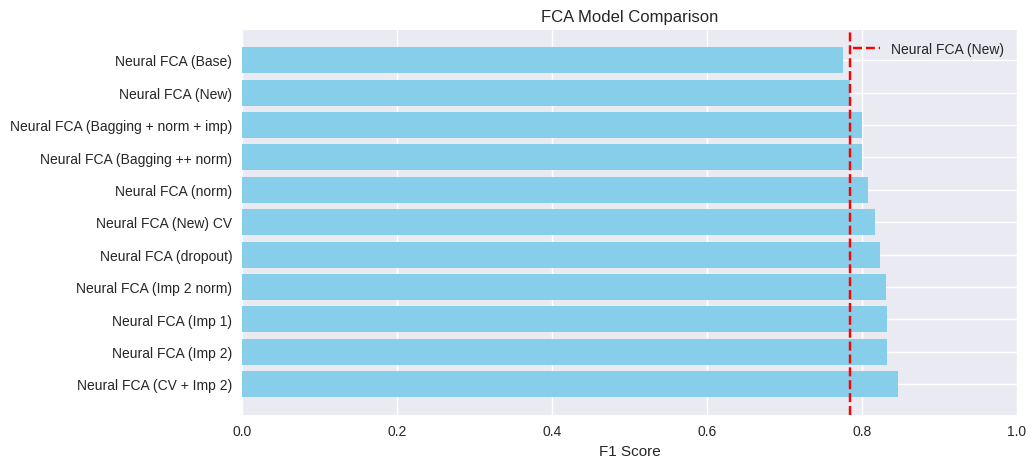

                                Model  F1 Score
7             Neural FCA (CV + Imp 2)  0.846680
6                  Neural FCA (Imp 2)  0.831825
5                  Neural FCA (Imp 1)  0.831825
8             Neural FCA (Imp 2 norm)  0.830476
4                Neural FCA (dropout)  0.823529
2                 Neural FCA (New) CV  0.816327
3                   Neural FCA (norm)  0.807692
9        Neural FCA (Bagging ++ norm)  0.800000
10  Neural FCA (Bagging + norm + imp)  0.800000
1                    Neural FCA (New)  0.784314
0                   Neural FCA (Base)  0.775510


In [ ]:
results_df_fca = pd.DataFrame(list(results_fca.items()), columns=['Model', 'F1 Score'])
results_df_fca = results_df_fca.sort_values(by='F1 Score', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(results_df_fca['Model'], results_df_fca['F1 Score'], color='skyblue')
plt.xlabel('F1 Score')
plt.title('FCA Model Comparison')
plt.xlim(0, 1.0)
plt.axvline(results_fca['Neural FCA (New)'], color='red', linestyle='--', label='Neural FCA (New)')
plt.legend()
plt.show()
print(results_df_fca)

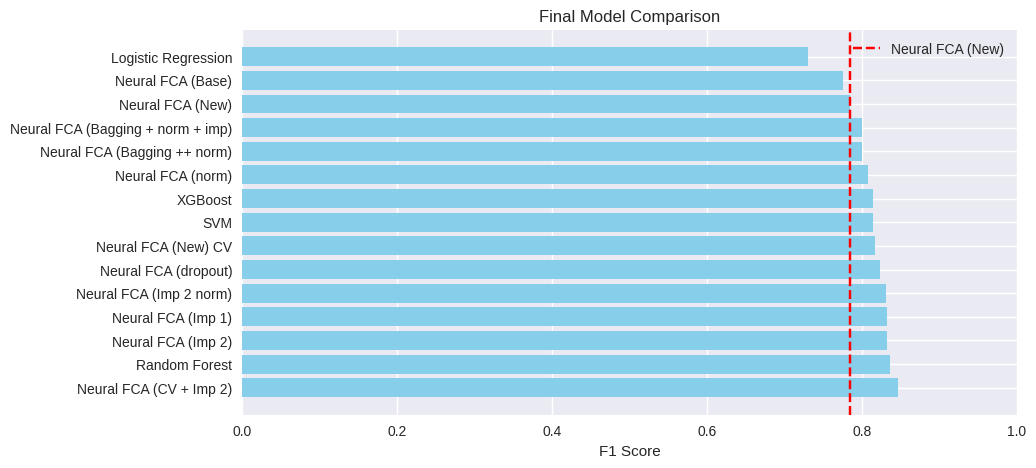

                                Model  F1 Score
11            Neural FCA (CV + Imp 2)  0.846680
1                       Random Forest  0.836364
10                 Neural FCA (Imp 2)  0.831825
9                  Neural FCA (Imp 1)  0.831825
12            Neural FCA (Imp 2 norm)  0.830476
8                Neural FCA (dropout)  0.823529
6                 Neural FCA (New) CV  0.816327
2                                 SVM  0.814815
3                             XGBoost  0.814815
7                   Neural FCA (norm)  0.807692
13       Neural FCA (Bagging ++ norm)  0.800000
14  Neural FCA (Bagging + norm + imp)  0.800000
5                    Neural FCA (New)  0.784314
4                   Neural FCA (Base)  0.775510
0                 Logistic Regression  0.730769


In [ ]:
merged = results_all | results_fca

results_df = pd.DataFrame(list(merged.items()), columns=['Model', 'F1 Score'])
results_df = results_df.sort_values(by='F1 Score', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(results_df['Model'], results_df['F1 Score'], color='skyblue')
plt.xlabel('F1 Score')
plt.title('Final Model Comparison')
plt.xlim(0, 1.0)
plt.axvline(results_fca['Neural FCA (New)'], color='red', linestyle='--', label='Neural FCA (New)')
plt.legend()
plt.show()
print(results_df)